This script trains a TrOCR-based OCR model specifically for recognizing vehicle identification numbers (VINs). It begins by defining a cleaning function that normalizes raw label text into a strict *VIN* format, correcting common character confusions, removing unwanted symbols, and ensuring a consistent 17-character VIN wrapped in asterisks. The script then loads image files and their corresponding label text files from training and validation directories, cleans the labels, filters out invalid samples, and constructs Hugging Face Dataset objects. After printing sample entries for verification, it loads the base TrOCR model and configures decoding parameters suitable for fixed-length VIN sequences. A data collator is defined to preprocess images and tokenize text labels during training. The script then initializes a Seq2SeqTrainer with specified hyperparameters, trains the model on the prepared datasets, evaluates it each epoch, and finally saves the fine-tuned model and processor. Example inference code is also printed to demonstrate how to apply the trained model to new VIN images.

In [ ]:
import os
import re
from pathlib import Path
import torch
from PIL import Image
from datasets import Dataset
from transformers import (
    TrOCRProcessor,
    VisionEncoderDecoderModel,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
)

# PATHS
ROOT = Path(r"D:\JLR_VIN_2549")
OUTPUT_DIR = ROOT / "best_trocr_v1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Output directory: {OUTPUT_DIR}")

# LABEL CLEANING FUNCTION - KEEP ASTERISKS!
def clean_vin_text(text):
    """
    Clean VIN labels but KEEP the asterisk format: *VIN*
    Examples:
    - *SAL1A2A4XSA605812* (good)
    - # SALIA 2A4XSA6000040* → *SAL1A2A4XSA6000040*
    - $SAL1A2AW0SA606646$ → *SAL1A2AW0SA606646*
    """
    # Convert to uppercase
    cleaned = text.upper()
    
    # Fix common OCR errors in the VIN part (middle 17 chars)
    # Don't touch the asterisks at start/end
    replacements = {
        'O': '0',  # Letter O to zero
        'I': '1',  # Letter I to one
        'Z': '2',  # Z might be 2
        'B': '8',  # B might be 8
        '/': '',   # Remove slashes
        '.': '',   # Remove dots
        ' ': '',   # Remove spaces
    }
    
    for wrong, correct in replacements.items():
        cleaned = cleaned.replace(wrong, correct)
    
    # Remove any characters that aren't A-Z, 0-9, or *
    cleaned = re.sub(r'[^A-Z0-9*]', '', cleaned)
    
    # Ensure format: *XXXXXXXXXXXXXXX* (19 chars total)
    # Extract the middle part (should be 17 chars of A-Z/0-9)
    middle = cleaned.strip('*')
    
    if len(middle) == 17:
        # Perfect! Return with asterisks
        return f"*{middle}*"
    elif len(middle) > 17:
        # Too long, truncate
        return f"*{middle[:17]}*"
    else:
        # Too short, pad with X
        padded = middle.ljust(17, 'X')
        return f"*{padded}*"

# LOAD DATA WITH CLEANING
def load_data(img_dir, lbl_dir):
    data = []
    
    # Get all image files
    image_files = []
    for ext in ['.jpg', '.jpeg', '.png']:
        image_files.extend(img_dir.glob(f"*{ext}"))
    
    print(f"Found {len(image_files)} images in {img_dir}")
    
    valid_count = 0
    for img_path in image_files:
        txt_path = lbl_dir / f"{img_path.stem}.txt"
        
        if txt_path.exists():
            raw_text = txt_path.read_text(encoding="utf-8").strip()
            
            # Skip empty lines or comment lines starting with #
            if raw_text.startswith('#') and '\n' in raw_text:
                # Take the second line if first line is comment
                lines = raw_text.split('\n')
                if len(lines) > 1:
                    raw_text = lines[1].strip()
            
            # Clean the label
            cleaned_text = clean_vin_text(raw_text)
            
            # Show cleaning process for first few samples
            if valid_count < 5:
                print(f"  Cleaning: '{raw_text}' -> '{cleaned_text}'")
            
            # Accept only 19-character cleaned VINs with asterisks
            if len(cleaned_text) == 19 and cleaned_text.startswith('*') and cleaned_text.endswith('*'):
                data.append({"image_path": str(img_path), "text": cleaned_text})
                valid_count += 1
            else:
                print(f"  Skipping {img_path.name}: '{cleaned_text}' (len={len(cleaned_text)})")
    
    print(f"  Valid samples: {valid_count}/{len(image_files)}")
    return Dataset.from_dict({
        "image_path": [d["image_path"] for d in data], 
        "text": [d["text"] for d in data]
    })

# LOAD DATASETS
print("\n" + "="*50)
print("LOADING TRAINING DATA...")
train_ds = load_data(ROOT / "ocr_train" / "images", ROOT / "ocr_train" / "labels")

print("\n" + "="*50)
print("LOADING VALIDATION DATA...")
val_ds = load_data(ROOT / "ocr_val" / "images", ROOT / "ocr_val" / "labels")

print(f"\nSUMMARY:")
print(f"Training samples: {len(train_ds)}")
print(f"Validation samples: {len(val_ds)}")

# CHECK DATA
if len(train_ds) == 0:
    print("ERROR: No valid training data!")
    # Try without strict asterisk checking
    print("Trying to load any 17-19 character data...")
    
    def load_any_data(img_dir, lbl_dir):
        data = []
        for img_path in img_dir.glob("*.jpg"):
            txt_path = lbl_dir / f"{img_path.stem}.txt"
            if txt_path.exists():
                text = txt_path.read_text(encoding="utf-8").strip()
                if 15 <= len(text) <= 25:  # Flexible length
                    data.append({"image_path": str(img_path), "text": text})
        return Dataset.from_dict({
            "image_path": [d["image_path"] for d in data], 
            "text": [d["text"] for d in data]
        })
    
    train_ds = load_any_data(ROOT / "ocr_train" / "images", ROOT / "ocr_train" / "labels")
    val_ds = load_any_data(ROOT / "ocr_val" / "images", ROOT / "ocr_val" / "labels")
    
    if len(train_ds) == 0:
        print("STILL no data found! Check your files.")
        exit(1)

# SHOW SAMPLE DATA
print("\nSAMPLE VINS (first 5):")
for i in range(min(5, len(train_ds))):
    sample = train_ds[i]
    print(f"  {Path(sample['image_path']).name}: '{sample['text']}'")

# LOAD MODEL
print("\n" + "="*50)
print("LOADING TrOCR MODEL...")
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-printed")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-printed")

# CONFIGURE MODEL FOR 19 CHARACTERS
model.config.decoder_start_token_id = processor.tokenizer.bos_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.eos_token_id = processor.tokenizer.eos_token_id
model.config.max_length = 25  # For 19 chars + buffer

# DATA COLLATOR
def data_collator(features):
    images = [Image.open(f["image_path"]).convert("RGB") for f in features]
    texts = [f["text"] for f in features]
    batch = processor(images, text=texts, padding="longest", truncation=True, max_length=25, return_tensors="pt")
    batch["labels"] = batch["labels"]
    return batch

# TRAINING SETTINGS
training_args = Seq2SeqTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=12,
    learning_rate=5e-5,
    warmup_steps=200,
    logging_steps=20,
    save_steps=999999,           # No checkpoints
    save_total_limit=1,
    evaluation_strategy="epoch",
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0,    # Windows safe
    remove_unused_columns=False,
    report_to=[],
    disable_tqdm=False,
    generation_max_length=25,
    predict_with_generate=True,
)

# TRAINER
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    tokenizer=processor.tokenizer,
)

# TRAIN
print("\n" + "="*80)
print("TRAINING STARTED")
print(f"Training on {len(train_ds)} samples")
print(f"VIN format: *17 characters* (19 chars total with asterisks)")
print("="*80 + "\n")

trainer.train()

# SAVE MODEL
final_path = OUTPUT_DIR / "best_trocr_v1"
trainer.save_model(str(final_path))
processor.save_pretrained(str(final_path))

print(f"\n" + "="*80)
print("✓ TRAINING COMPLETE")
print(f"✓ Model saved to: {final_path}")
print("="*80)

print(f'''
TO USE YOUR MODEL:

from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image

# Load trained model
processor = TrOCRProcessor.from_pretrained(r"{final_path}")
model = VisionEncoderDecoderModel.from_pretrained(r"{final_path}")

# Read image
img = Image.open("your_vin_image.jpg").convert("RGB")

# Predict
pixel_values = processor(img, return_tensors="pt").pixel_values
generated_ids = model.generate(pixel_values, max_length=25)
vin = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print(f"VIN: {{vin}}")  # Will output: *SAL1A2A4XSA605812*
''')

Output directory: D:\JLR_VIN_2549\best_trocr_v1

LOADING TRAINING DATA...
Found 2385 images in D:\JLR_VIN_2549\ocr_train\images
  Cleaning: '*SAL119E90SA606112*' -> '*SAL119E90SA606112*'
  Cleaning: '*SAL119E91SA606796*' -> '*SAL119E91SA606796*'
  Cleaning: '*SAL119E92SA606001*' -> '*SAL119E92SA606001*'
  Cleaning: '*SAL119E95SA606669*' -> '*SAL119E95SA606669*'
  Cleaning: '*SAL119E96SA605885*' -> '*SAL119E96SA605885*'
  Valid samples: 2385/2385

LOADING VALIDATION DATA...
Found 417 images in D:\JLR_VIN_2549\ocr_val\images
  Cleaning: '*SAL119E96SA606793*' -> '*SAL119E96SA606793*'
  Cleaning: '*SAL1A2A40SA606662*' -> '*SAL1A2A40SA606662*'
  Cleaning: '*SAL1A2A40SA606886*' -> '*SAL1A2A40SA606886*'
  Cleaning: '*SAL1A2A41SA606878*' -> '*SAL1A2A41SA606878*'
  Cleaning: '*SAL1A2A42SA606923*' -> '*SAL1A2A42SA606923*'
  Valid samples: 417/417

SUMMARY:
Training samples: 2385
Validation samples: 417

SAMPLE VINS (first 5):
  SAL119E90SA606112_train_1-VIN_-_SAL119E90SA606112_.jpg: '*SAL119E90S

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.48.0"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder


TRAINING STARTED
Training on 2385 samples
VIN format: *17 characters* (19 chars total with asterisks)



Epoch,Training Loss,Validation Loss
1,0.235200,0.539413
2,0.104100,0.131233
3,0.055300,0.060623
4,0.051600,0.025136
5,0.038300,0.018685
6,0.016600,0.012080
7,0.014800,0.009797
8,0.007700,0.011978
9,0.001000,0.003380
10,0.000200,0.002903


d:\JLR_VIN_2549\.venv\Lib\site-packages\transformers\modeling_utils.py:2758: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 25}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(



✓ TRAINING COMPLETE
✓ Model saved to: D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1

TO USE YOUR MODEL:

from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image

# Load trained model
processor = TrOCRProcessor.from_pretrained(r"D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1")
model = VisionEncoderDecoderModel.from_pretrained(r"D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1")

# Read image
img = Image.open("your_vin_image.jpg").convert("RGB")

# Predict
pixel_values = processor(img, return_tensors="pt").pixel_values
generated_ids = model.generate(pixel_values, max_length=25)
vin = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print(f"VIN: {vin}")  # Will output: *SAL1A2A4XSA605812*



This script evaluates a fine-tuned TrOCR VIN OCR model on a labeled test set of images. It loads each test image from a folder and reads the corresponding ground-truth VIN from a .txt file with the same name, then cleans and normalizes the label using the same clean_vin_text function used in training. For every image, it runs the model to predict the VIN, prints the ground-truth and predicted values, and stores them for analysis. After processing all samples, it computes the exact VIN match accuracy (how many full VINs were predicted correctly) and the character-level accuracy (the proportion of correctly predicted characters over all characters). It also builds a character-level confusion matrix over A–Z, 0–9, and *, showing how often each true character is misrecognized as another, and visualizes this confusion matrix as a heatmap using matplotlib and seaborn to help understand where the model is making systematic mistakes.

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.48.0"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

Model loaded.
Found 160 test images
SAL119E95SA606669_test_4-VIN_-_SAL119E95SA606669_.jpg → GT: *SAL119E95SA606669* | Pred: *SAL119E95SA606669*
SAL1A2A43SA606882_test_27-VIN_-_SAL1A2A43SA606882_.jpg → GT: *SAL1A2A43SA606882* | Pred: *SAL1A2A43SA606882*
SAL1A2A47SA606660_test_48-VIN_-_SAL1A2A47SA606660_.jpg → GT: *SAL1A2A47SA606660* | Pred: *SAL1A2A47SA606660*
SAL1A2A48SA605985_test_53-VIN_-_SAL1A2A48SA605985_.jpg → GT: *SAL1A2A48SA605985* | Pred: *SAL1A2A48SA605985*
SAL1A2A49SA606627_test_63-VIN_-_SAL1A2A49SA606627_.jpg → GT: *SAL1A2A49SA606627* | Pred: *SAL1A2A49SA606627*
SAL1A2A92SA606173_test_82-VIN_-_SAL1A2A92SA606173_.jpg → GT: *SAL1A2A92SA606173* | Pred: *SAL1A2A92SA606173*
SAL1A2AW0SA605416_test_104-VIN_-_SAL1A2AW0SA605416_.jpg → GT: *SAL1A2AW0SA605416* | Pred: *SAL1A2AW0SA605416*
SAL1A2AW0SA606839_test_122-VIN_-_SAL1A2AW0SA606839_.jpg → GT: *SAL1A2AW0SA606839* | Pred: *SAL1A2AW0SA606839*
SAL1A2AW1SA606607_test_147-VIN_-_SAL1A2AW1SA606607_.jpg → GT: *SAL1A2AW1SA606607* | Pred: *

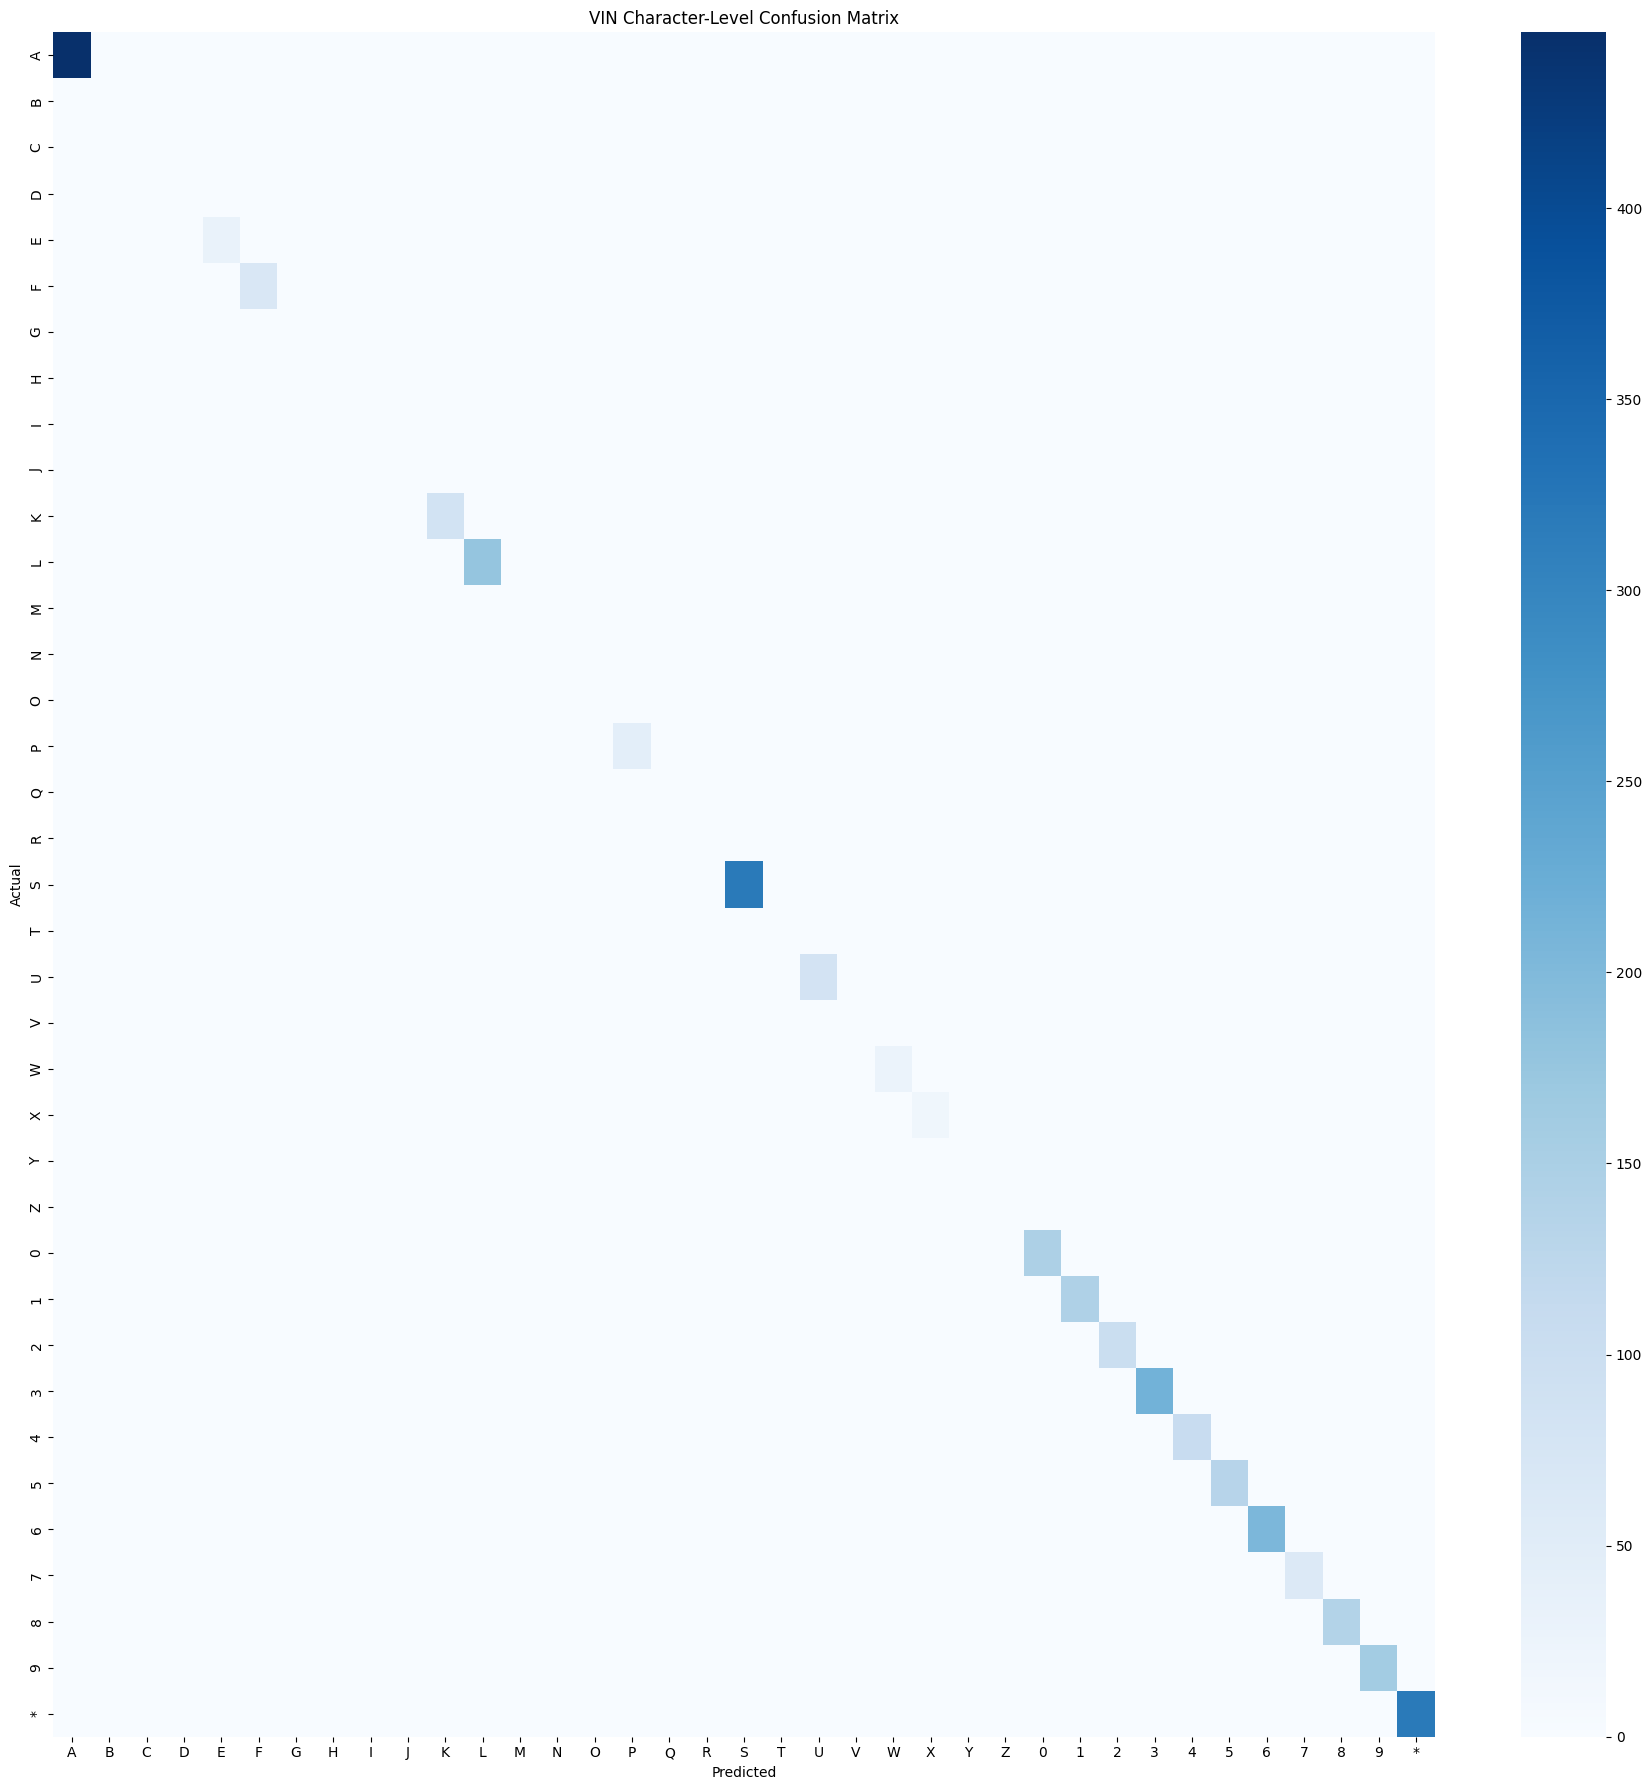

In [3]:
import os
import re
from pathlib import Path
from PIL import Image

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# SAME CLEANING FUNCTION YOU USED FOR TRAINING

def clean_vin_text(text):
    cleaned = text.upper()
    replacements = {
        'O': '0',
        'I': '1',
        'Z': '2',
        'B': '8',
        '/': '',
        '.': '',
        ' ': '',
    }
    for wrong, correct in replacements.items():
        cleaned = cleaned.replace(wrong, correct)

    cleaned = re.sub(r'[^A-Z0-9*]', '', cleaned)
    middle = cleaned.strip('*')

    if len(middle) == 17:
        return f"*{middle}*"
    elif len(middle) > 17:
        return f"*{middle[:17]}*"
    else:
        middle = middle.ljust(17, 'X')
        return f"*{middle}*"



# PATHS

TEST_IMG_DIR = Path(r"D:\JLR_VIN_2549\ocr_test\images")
TEST_LBL_DIR = Path(r"D:\JLR_VIN_2549\ocr_test\labels")
MODEL_PATH = Path(r"D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1")


# LOAD MODEL

processor = TrOCRProcessor.from_pretrained(str(MODEL_PATH))
model = VisionEncoderDecoderModel.from_pretrained(str(MODEL_PATH))
model.eval()

print("Model loaded.")



# LOAD TEST DATA

test_images = sorted([p for p in TEST_IMG_DIR.glob("*.jpg")])

gt_texts = []
pred_texts = []
failed_samples = []

print(f"Found {len(test_images)} test images")

for img_path in test_images:
    lbl_path = TEST_LBL_DIR / f"{img_path.stem}.txt"

    if not lbl_path.exists():
        print(f"⚠ No label file found for: {img_path.name}")
        continue

    raw_lbl = lbl_path.read_text().strip()
    gt = clean_vin_text(raw_lbl)

    img = Image.open(img_path).convert("RGB")

    # Predict VIN
    pixel_values = processor(img, return_tensors="pt").pixel_values
    with torch.no_grad():
        ids = model.generate(pixel_values, max_length=25)
        pred = processor.batch_decode(ids, skip_special_tokens=True)[0]

    gt_texts.append(gt)
    pred_texts.append(pred)

    print(f"{img_path.name} → GT: {gt} | Pred: {pred}")



# METRICS


# Exact Match Accuracy
exact_matches = sum([gt == pred for gt, pred in zip(gt_texts, pred_texts)])
exact_accuracy = exact_matches / len(gt_texts)

print("\n========== EXACT VIN MATCH ACCURACY ==========")
print(f"Exact Match Accuracy: {exact_accuracy:.4f}")
print("==============================================")


# CHARACTER-LEVEL CONFUSION MATRIX

chars = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789*")
char_to_idx = {c: i for i, c in enumerate(chars)}
matrix = np.zeros((len(chars), len(chars)), dtype=int)

total_chars = 0
correct_chars = 0

for gt, pred in zip(gt_texts, pred_texts):
    # Pad to same length
    L = max(len(gt), len(pred))
    gt = gt.ljust(L, "*")
    pred = pred.ljust(L, "*")

    for g, p in zip(gt, pred):
        if g in char_to_idx and p in char_to_idx:
            matrix[char_to_idx[g], char_to_idx[p]] += 1

        if g == p:
            correct_chars += 1

        total_chars += 1

char_accuracy = correct_chars / total_chars

print("\n========== CHARACTER-LEVEL ACCURACY ==========")
print(f"Character Accuracy: {char_accuracy:.4f}")
print("==============================================")


# PLOT CONFUSION MATRIX

plt.figure(figsize=(18, 18))
sns.heatmap(matrix, xticklabels=chars, yticklabels=chars, cmap="Blues", fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("VIN Character-Level Confusion Matrix")
plt.tight_layout()
plt.show()


This script evaluates a fine-tuned TrOCR VIN OCR model on a labeled test dataset. It loads each test image along with its corresponding ground-truth VIN from a .txt file, cleans both the ground truth and model predictions using a consistent VIN-normalization function, and then compares them. For every sample, the script prints the raw and cleaned VINs, computes whether the full VIN matches exactly, and measures how many individual characters were predicted correctly. After processing all images, it calculates overall exact-match accuracy, character-level accuracy, and builds a full character confusion matrix showing where the model confuses one character for another. All detailed results are saved into a CSV file, a summary of the evaluation is written to a text file, and a confusion-matrix heatmap is generated as an image. This provides a complete and structured evaluation of the OCR model’s performance on the VIN dataset.

d:\JLR_VIN_2549\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Using device: cpu


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.48.0"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

Model loaded.
Found 160 test images

SAL119E95SA606669_test_4-VIN_-_SAL119E95SA606669_.jpg →
   GT raw   : *SAL119E95SA606669*
   GT clean : *SAL119E95SA606669*
   Pred raw : *SAL119E95SA606669*
   Pred clean: *SAL119E95SA606669*
------------------------------------------------------------
SAL1A2A43SA606882_test_27-VIN_-_SAL1A2A43SA606882_.jpg →
   GT raw   : *SAL1A2A43SA606882*
   GT clean : *SAL1A2A43SA606882*
   Pred raw : *SAL1A2A43SA606882*
   Pred clean: *SAL1A2A43SA606882*
------------------------------------------------------------
SAL1A2A47SA606660_test_48-VIN_-_SAL1A2A47SA606660_.jpg →
   GT raw   : *SAL1A2A47SA606660*
   GT clean : *SAL1A2A47SA606660*
   Pred raw : *SAL1A2A47SA606660*
   Pred clean: *SAL1A2A47SA606660*
------------------------------------------------------------
SAL1A2A48SA605985_test_53-VIN_-_SAL1A2A48SA605985_.jpg →
   GT raw   : *SAL1A2A48SA605985*
   GT clean : *SAL1A2A48SA605985*
   Pred raw : *SAL1A2A48SA605985*
   Pred clean: *SAL1A2A48SA605985*
-----

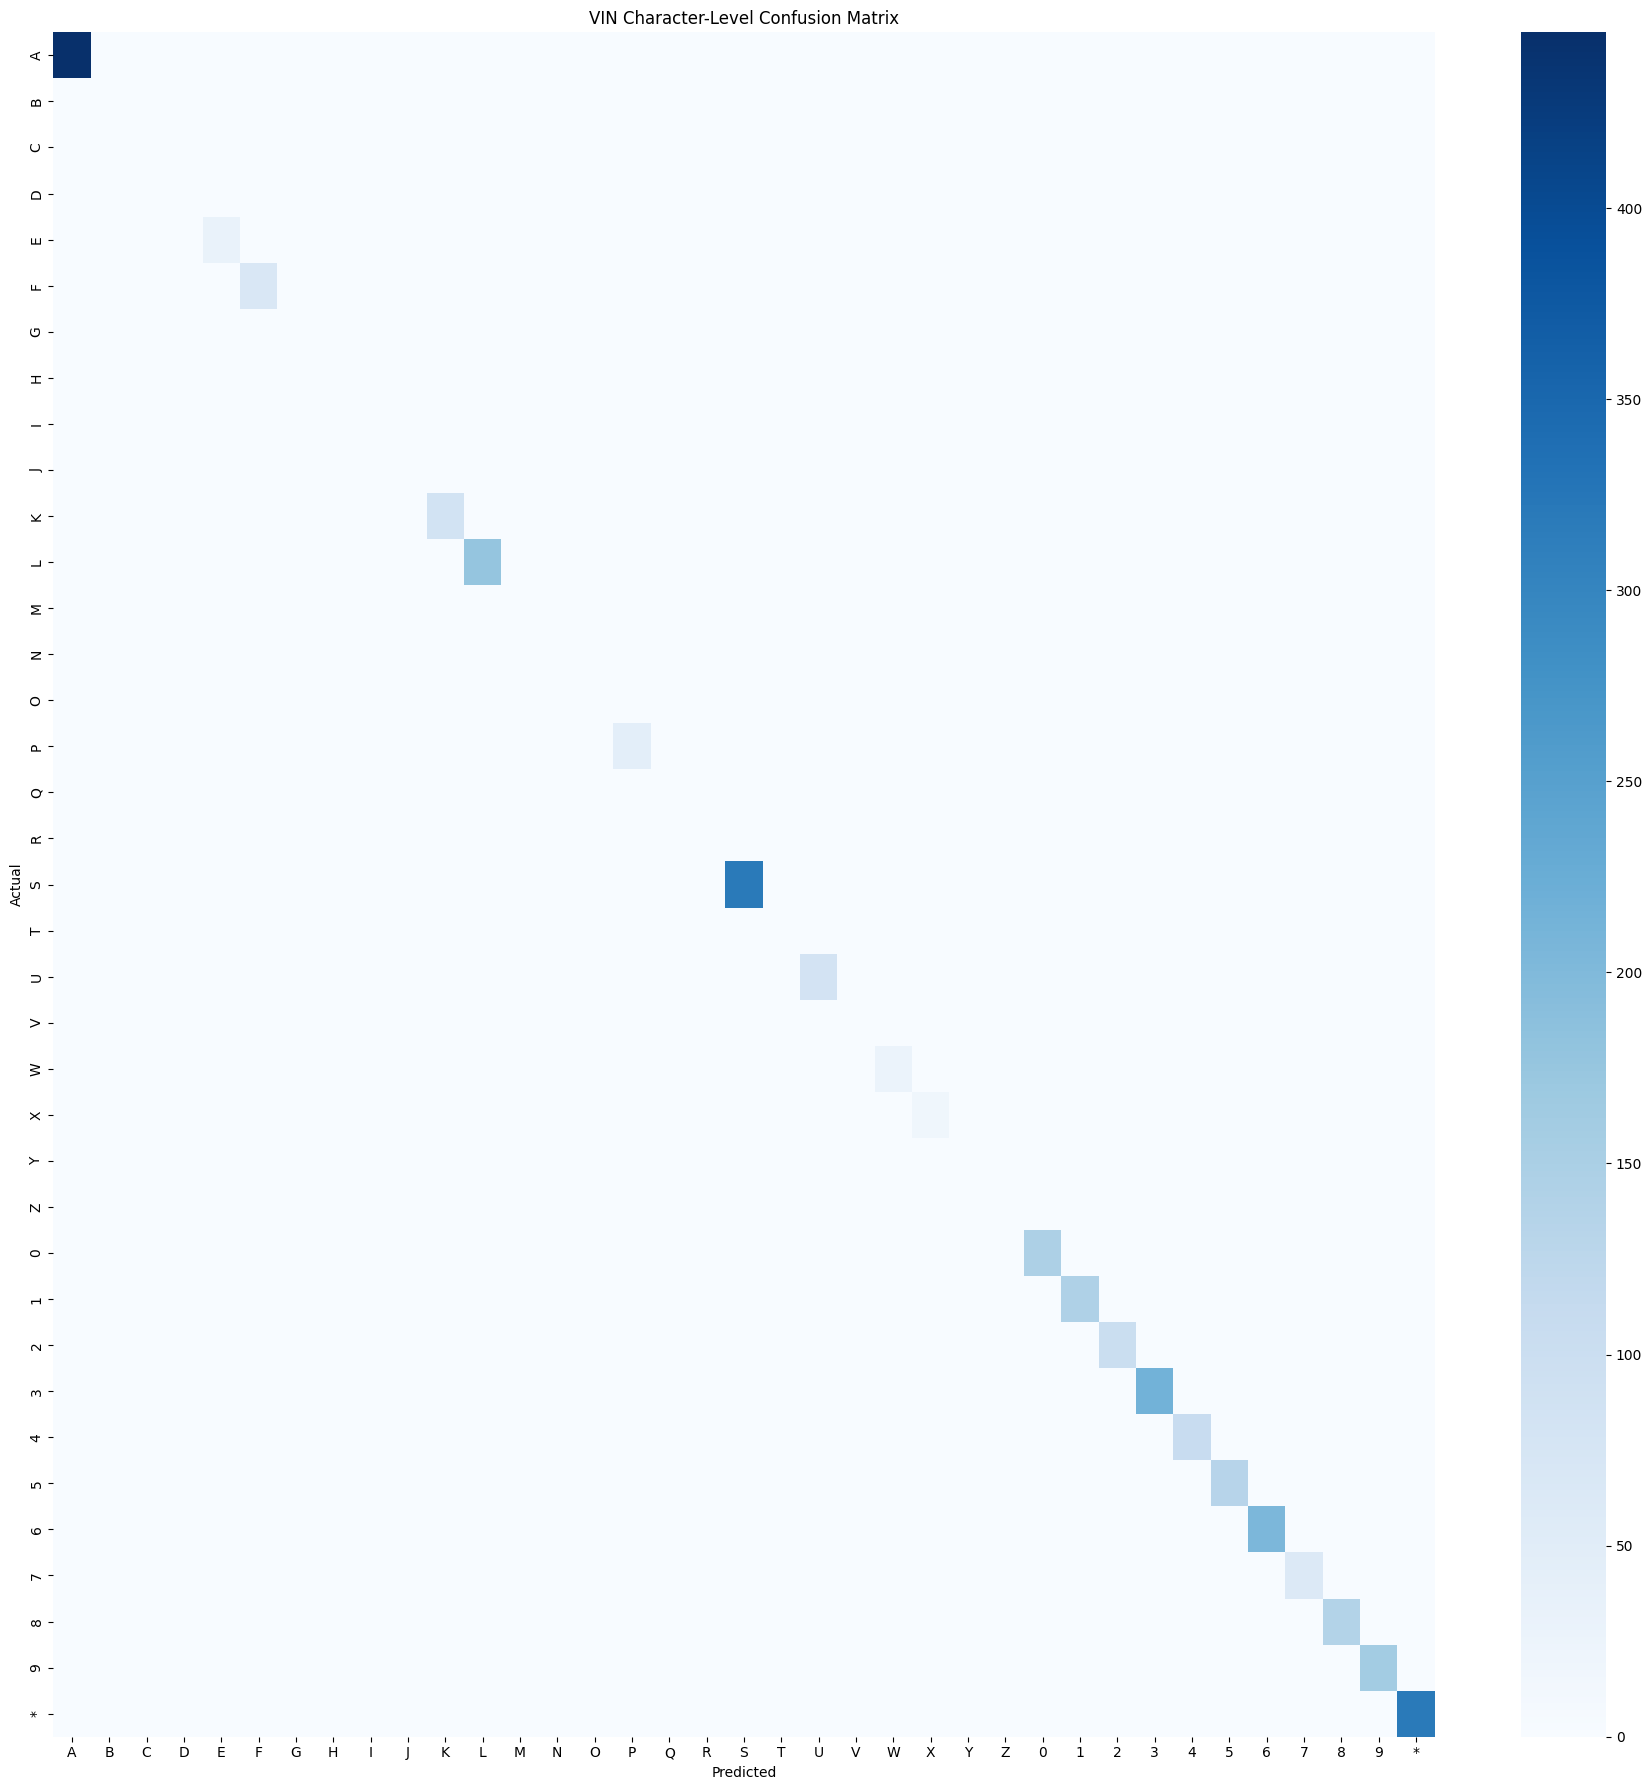


Done. Check:
  - D:\JLR_VIN_2549\ocr_test\eval_results1\ocr_test_results.csv  (per-image details)
  - D:\JLR_VIN_2549\ocr_test\eval_results1\ocr_test_summary.txt  (overall metrics)
  - D:\JLR_VIN_2549\ocr_test\eval_results1\ocr_test_confusion_matrix.png (character confusion heatmap)


In [ ]:
import os
import re
from pathlib import Path
from datetime import datetime

from PIL import Image
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import csv

from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# CLEANING FUNCTION (same logic)

def clean_vin_text(text: str) -> str:
    """
    Clean and normalize VIN to *17-CHAR* format.
    """
    cleaned = text.upper()
    replacements = {
        'O': '0',
        'I': '1',
        'Z': '2',
        'B': '8',
        '/': '',
        '.': '',
        ' ': '',
    }
    for wrong, correct in replacements.items():
        cleaned = cleaned.replace(wrong, correct)

    # Keep only A-Z, 0-9, *
    cleaned = re.sub(r'[^A-Z0-9*]', '', cleaned)

    middle = cleaned.strip('*')

    if len(middle) == 17:
        return f"*{middle}*"
    elif len(middle) > 17:
        return f"*{middle[:17]}*"
    else:
        middle = middle.ljust(17, 'X')
        return f"*{middle}*"


#  PATHS 

TEST_IMG_DIR = Path(r"D:\JLR_VIN_2549\ocr_test\images")
TEST_LBL_DIR = Path(r"D:\JLR_VIN_2549\ocr_test\labels")
MODEL_PATH   = Path(r"D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1")

# Where to save results
RESULTS_DIR  = TEST_IMG_DIR.parent / "eval_results1"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV  = RESULTS_DIR / "ocr_test_results.csv"
SUMMARY_TXT  = RESULTS_DIR / "ocr_test_summary.txt"
CONFUSION_PNG = RESULTS_DIR / "ocr_test_confusion_matrix.png"


# LOAD MODEL 

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

processor = TrOCRProcessor.from_pretrained(str(MODEL_PATH))
model = VisionEncoderDecoderModel.from_pretrained(str(MODEL_PATH))
model.to(device)
model.eval()

print("Model loaded.")


# LOAD TEST DATA & EVALUATE 

test_images = sorted([p for p in TEST_IMG_DIR.glob("*.jpg")])

gt_texts_clean = []
pred_texts_clean = []
gt_texts_raw = []
pred_texts_raw = []
image_names = []

print(f"Found {len(test_images)} test images\n")

for img_path in test_images:
    lbl_path = TEST_LBL_DIR / f"{img_path.stem}.txt"

    if not lbl_path.exists():
        print(f"⚠ No label file found for: {img_path.name}")
        continue

    raw_lbl = lbl_path.read_text().strip()
    gt_clean = clean_vin_text(raw_lbl)

    img = Image.open(img_path).convert("RGB")

    # Predict VIN
    pixel_values = processor(images=img, return_tensors="pt").pixel_values.to(device)

    with torch.no_grad():
        ids = model.generate(pixel_values, max_length=25)
        pred_raw = processor.batch_decode(ids, skip_special_tokens=True)[0]

    pred_clean = clean_vin_text(pred_raw)

    gt_texts_raw.append(raw_lbl)
    pred_texts_raw.append(pred_raw)
    gt_texts_clean.append(gt_clean)
    pred_texts_clean.append(pred_clean)
    image_names.append(img_path.name)
    print("------")
    print(gt_clean.dtype, pred_clean.dtype)

    print(f"{img_path.name} →")
    print(f"   GT raw   : {raw_lbl}")
    print(f"   GT clean : {gt_clean}")
    print(f"   Pred raw : {pred_raw}")
    print(f"   Pred clean: {pred_clean}")
    print("-" * 60)


# METRICS 

if not gt_texts_clean:
    print("No valid test samples found. Exiting.")
    exit(0)

# Exact Match Accuracy (clean VINs)
exact_matches = sum(
    1 for gt, pred in zip(gt_texts_clean, pred_texts_clean) if gt == pred
)
exact_accuracy = exact_matches / len(gt_texts_clean)

print("\n========== EXACT VIN MATCH ACCURACY ==========")
print(f"Samples: {len(gt_texts_clean)}")
print(f"Exact Match Accuracy: {exact_accuracy:.4f}")
print("==============================================")

# Character-level confusion matrix
chars = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789*")
char_to_idx = {c: i for i, c in enumerate(chars)}
matrix = np.zeros((len(chars), len(chars)), dtype=int)

total_chars = 0
correct_chars = 0

# Also store per-sample char-level stats
per_sample_correct_chars = []
per_sample_total_chars = []
per_sample_char_acc = []

for gt, pred in zip(gt_texts_clean, pred_texts_clean):
    L = max(len(gt), len(pred))
    gt_padded = gt.ljust(L, "*")
    pred_padded = pred.ljust(L, "*")

    sample_correct = 0
    sample_total = 0

    for g, p in zip(gt_padded, pred_padded):
        if g in char_to_idx and p in char_to_idx:
            matrix[char_to_idx[g], char_to_idx[p]] += 1

        if g == p:
            correct_chars += 1
            sample_correct += 1

        total_chars += 1
        sample_total += 1

    per_sample_correct_chars.append(sample_correct)
    per_sample_total_chars.append(sample_total)
    per_sample_char_acc.append(sample_correct / sample_total if sample_total > 0 else 0.0)

char_accuracy = correct_chars / total_chars

print("\n========== CHARACTER-LEVEL ACCURACY ==========")
print(f"Total characters (all samples): {total_chars}")
print(f"Character Accuracy: {char_accuracy:.4f}")
print("==============================================\n")


# SAVE PER-SAMPLE RESULTS TO CSV 

print(f"Saving detailed results to: {RESULTS_CSV}")

with open(RESULTS_CSV, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "image",
        "gt_raw",
        "gt_clean",
        "pred_raw",
        "pred_clean",
        "exact_match",
        "sample_char_accuracy",
        "sample_correct_chars",
        "sample_total_chars",
    ])

    for name, gt_raw, gt_c, pr_raw, pr_c, c_corr, c_tot, c_acc in zip(
        image_names,
        gt_texts_raw,
        gt_texts_clean,
        pred_texts_raw,
        pred_texts_clean,
        per_sample_correct_chars,
        per_sample_total_chars,
        per_sample_char_acc,
    ):
        writer.writerow([
            name,
            gt_raw,
            gt_c,
            pr_raw,
            pr_c,
            int(gt_c == pr_c),       # 1 if exact match, 0 otherwise
            f"{c_acc:.4f}",
            c_corr,
            c_tot,
        ])


#  SAVE SUMMARY TO TEXT FILE 

print(f"Saving summary to: {SUMMARY_TXT}")

with open(SUMMARY_TXT, "w", encoding="utf-8") as f:
    f.write("VIN OCR Evaluation Summary\n")
    f.write("==========================\n\n")
    f.write(f"Date: {datetime.now()}\n\n")
    f.write(f"Number of samples        : {len(gt_texts_clean)}\n")
    f.write(f"Exact matches            : {exact_matches}\n")
    f.write(f"Exact match accuracy     : {exact_accuracy:.4f}\n\n")
    f.write(f"Total characters         : {total_chars}\n")
    f.write(f"Character-level accuracy : {char_accuracy:.4f}\n\n")
    f.write("Note: GT and predictions were cleaned using clean_vin_text().\n")


# PLOT & SAVE CONFUSION MATRIX 

plt.figure(figsize=(18, 18))
sns.heatmap(
    matrix,
    xticklabels=chars,
    yticklabels=chars,
    cmap="Blues",
    fmt="d"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("VIN Character-Level Confusion Matrix")
plt.tight_layout()

print(f"Saving confusion matrix image to: {CONFUSION_PNG}")
plt.savefig(CONFUSION_PNG)
plt.show()

print("\nDone. Check:")
print(f"  - {RESULTS_CSV}  (per-image details)")
print(f"  - {SUMMARY_TXT}  (overall metrics)")
print(f"  - {CONFUSION_PNG} (character confusion heatmap)")


This VIN OCR GUI provides a complete environment for testing and evaluating a fine-tuned TrOCR model on VIN images. It automatically extracts the ground-truth VIN from each filename, applies the same cleaning rules used during training, and compares it with the model’s prediction. Users can load single images, multiple images, or full folders and instantly see predictions, raw OCR output, ground truth, and match results. After processing all images, the GUI calculates image-level accuracy, character-level accuracy, and character-level F1 scores (micro and macro), giving a detailed view of how well the model performs. The tool is designed for fast validation, error inspection, and performance benchmarking, not training, making it ideal for model testing and dataset quality checks.

Point-Form Version (Concise Key Features)
🔹 Main Features

1. Load single images, multiple images, or entire folders

2. Automatic ground-truth extraction from filenames

3. Applies the same VIN cleaning logic used in training

4. Displays GT VIN, predicted VIN, raw OCR, match status (✔/✖)

Real-time table and image preview

🔹 Evaluation Process

1. Filename → extract VIN before _ → clean → ground truth

2. Model → raw OCR → clean → prediction

3. Compare ground truth vs prediction at:

Full VIN level (match/nomatch)

Per-character level

🔹 Metrics Produced

Image-level accuracy (correct vs failed VINs)

Character accuracy (% of characters predicted correctly)

F1-micro (overall precision/recall across all characters)

F1-macro (average performance across unique characters)

🔹 What the GUI Does Not Do

1. Does not train or fine-tune the model

2. Does not require CSV/label files

3. Does not compute CER/WER unless added later

In [1]:
import os
import sys
import re
from pathlib import Path
from typing import List, Dict, Any, Optional

from PIL import Image
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from sklearn.metrics import f1_score

from PySide6 import QtCore, QtGui, QtWidgets


# BASE DIR (supports both normal run and PyInstaller bundle)
def get_base_dir() -> Path:
    """
    Return base directory whether running:
    - from a normal .py script
    - from a Jupyter / interactive session (no __file__)
    - from a PyInstaller bundle (sys._MEIPASS)
    """
    # PyInstaller bundle
    if hasattr(sys, "_MEIPASS"):
        return Path(sys._MEIPASS)

    # Normal .py script
    if "__file__" in globals():
        return Path(__file__).resolve().parent

    # Notebook / interactive fallback
    return Path.cwd()


BASE_DIR = get_base_dir()

# CONFIG / PATHS FOR DEPLOYMENT

MODEL_PATH = r"D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1"

# Optional: default folder when user clicks "Open Folder"
DEFAULT_IMAGES_DIR = BASE_DIR / "images"  # can be empty; user can browse anywhere


# SAME CLEANING FUNCTION YOU USED FOR TRAINING / EVAL

def clean_vin_text(text: str) -> str:
    cleaned = text.upper()
    replacements = {
        'O': '0',
        'I': '1',
        'Z': '2',
        'B': '8',
        '/': '',
        '.': '',
        ' ': '',
    }
    for wrong, correct in replacements.items():
        cleaned = cleaned.replace(wrong, correct)

    cleaned = re.sub(r'[^A-Z0-9*]', '', cleaned)
    middle = cleaned.strip('*')

    if len(middle) == 17:
        return f"*{middle}*"
    elif len(middle) > 17:
        return f"*{middle[:17]}*"
    else:
        middle = middle.ljust(17, 'X')
        return f"*{middle}*"


# LOAD MODEL (GLOBAL, SHARED BY WORKER)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

processor = TrOCRProcessor.from_pretrained(str(MODEL_PATH))
model = VisionEncoderDecoderModel.from_pretrained(str(MODEL_PATH))
model.to(device)
model.eval()
print("Model loaded from:", MODEL_PATH)


# WORKER THREAD: RUN OCR ON A LIST OF IMAGES (NON-BLOCKING GUI)

class InferenceWorker(QtCore.QThread):
    """
    Runs OCR on a list of image paths.
    No labels, no metrics – just predictions.
    """
    progress  = QtCore.Signal(int)
    item_done = QtCore.Signal(dict)
    finished  = QtCore.Signal()

    def __init__(self, paths: List[str], parent: QtCore.QObject = None):
        super().__init__(parent)
        self.paths = paths
        self._stop = False

    def stop(self):
        self._stop = True

    def run(self):
        total = len(self.paths)
        if total == 0:
            self.finished.emit()
            return

        for idx, img_path in enumerate(self.paths, start=1):
            if self._stop:
                break

            try:
                img = Image.open(img_path).convert("RGB")
            except Exception as e:
                print(f"Error opening image {img_path}: {e}")
                self.item_done.emit(
                    {
                        "path": img_path,
                        "image_name": Path(img_path).name,
                        "pred_raw": f"[ERROR: {e}]",
                        "pred_clean": "",
                    }
                )
                self.progress.emit(int(idx * 100 / total))
                continue

            # Predict VIN
            try:
                pixel_values = processor(images=img, return_tensors="pt").pixel_values.to(device)
                with torch.no_grad():
                    ids = model.generate(pixel_values, max_length=25)
                    pred_raw = processor.batch_decode(ids, skip_special_tokens=True)[0]
            except Exception as e:
                pred_raw = f"[ERROR: {e}]"

            if pred_raw.startswith("[ERROR"):
                pred_clean = ""
            else:
                pred_clean = clean_vin_text(pred_raw)

            row = {
                "path": img_path,
                "image_name": Path(img_path).name,
                "pred_raw": pred_raw,
                "pred_clean": pred_clean,
            }

            self.item_done.emit(row)
            self.progress.emit(int(idx * 100 / total))

        self.finished.emit()


# MAIN WINDOW

class MainWindow(QtWidgets.QMainWindow):
    def __init__(self):
        super().__init__()

        self.setWindowTitle("VIN OCR – TrOCR Deployment (With Metrics)")
        self.resize(1400, 800)

        self.rows: List[Dict[str, Any]] = []
        self.worker: Optional[InferenceWorker] = None

        self._setup_ui()
        self._connect_signals()

    #  UI LAYOUT
    def _setup_ui(self):
        # Left: image preview
        self.imageLabel = QtWidgets.QLabel("Preview")
        self.imageLabel.setAlignment(QtCore.Qt.AlignCenter)
        self.imageLabel.setMinimumSize(800, 600)
        self.imageLabel.setStyleSheet(
            """
            QLabel {
                background: #111;
                color: #999;
                border: 2px solid #444;
                font-size: 12px;
            }
            """
        )

        # Controls group (top-left under preview)
        control_group = QtWidgets.QGroupBox("Controls")
        control_layout = QtWidgets.QGridLayout(control_group)

        self.btnOpenImages = QtWidgets.QPushButton("📁 Open Image(s)")
        self.btnOpenFolder = QtWidgets.QPushButton("📂 Open Folder")
        self.btnClear      = QtWidgets.QPushButton("🗑 Clear")
        self.btnExit       = QtWidgets.QPushButton("❌ Exit")

        self.lblInfo = QtWidgets.QLabel(
            f"Model path: {MODEL_PATH}"
        )

        self.progress = QtWidgets.QProgressBar()
        self.progress.setRange(0, 100)
        self.progress.setValue(0)

        control_layout.addWidget(self.lblInfo,       0, 0, 1, 4)
        control_layout.addWidget(self.btnOpenImages, 1, 0)
        control_layout.addWidget(self.btnOpenFolder, 1, 1)
        control_layout.addWidget(self.btnClear,      1, 2)
        control_layout.addWidget(self.btnExit,       1, 3)
        control_layout.addWidget(self.progress,      2, 0, 1, 4)

        # Right: table with predictions + GT + match
        self.table = QtWidgets.QTableWidget(0, 6)
        self.table.setHorizontalHeaderLabels(
            ["Image", "GT VIN", "VIN (clean)", "VIN (raw)", "Match?", "Details"]
        )
        self.table.horizontalHeader().setStretchLastSection(True)
        self.table.setSelectionBehavior(QtWidgets.QAbstractItemView.SelectRows)
        self.table.setEditTriggers(QtWidgets.QAbstractItemView.NoEditTriggers)
        self.table.setColumnWidth(0, 250)  # Image
        self.table.setColumnWidth(1, 200)  # GT VIN
        self.table.setColumnWidth(2, 200)  # VIN (clean)
        self.table.setColumnWidth(3, 260)  # VIN (raw)
        self.table.setColumnWidth(4, 80)   # Match?
        self.table.setColumnWidth(5, 300)  # Details

        # Layout the main window (left preview + controls, right table)
        root_widget = QtWidgets.QWidget()
        main_layout = QtWidgets.QHBoxLayout(root_widget)

        left_layout = QtWidgets.QVBoxLayout()
        left_layout.addWidget(self.imageLabel, 3)
        left_layout.addWidget(control_group, 1)

        right_layout = QtWidgets.QVBoxLayout()
        right_layout.addWidget(QtWidgets.QLabel("<b>Results:</b>"))
        right_layout.addWidget(self.table, 1)

        main_layout.addLayout(left_layout, 2)
        main_layout.addLayout(right_layout, 1)

        self.setCentralWidget(root_widget)

    def _connect_signals(self):
        self.btnOpenImages.clicked.connect(self.open_images)
        self.btnOpenFolder.clicked.connect(self.open_folder)
        self.btnClear.clicked.connect(self.clear_results)
        self.btnExit.clicked.connect(self.exit_application)
        self.table.itemSelectionChanged.connect(self.on_row_selected)

    #  Worker lifecycle
    def _stop_worker(self):
        if self.worker and self.worker.isRunning():
            self.worker.stop()
            self.worker.wait(2000)

    def closeEvent(self, event: QtGui.QCloseEvent):
        self._stop_worker()
        event.accept()

    def exit_application(self):
        self._stop_worker()
        self.close()

    #  Actions 
    def clear_results(self):
        self._stop_worker()
        self.rows.clear()
        self.table.setRowCount(0)
        self.imageLabel.clear()
        self.imageLabel.setText("Preview")
        self.progress.setValue(0)

    def open_images(self):
        valid_exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

        files, _ = QtWidgets.QFileDialog.getOpenFileNames(
            self,
            "Select Image(s)",
            str(DEFAULT_IMAGES_DIR if DEFAULT_IMAGES_DIR.exists() else BASE_DIR),
            "Images (*.png *.jpg *.jpeg *.bmp *.tif *.tiff);;All Files (*)",
        )
        # filter + dedupe
        paths = [f for f in files if Path(f).suffix.lower() in valid_exts]
        paths = sorted(set(paths))  # <--- avoid duplicates
        if not paths:
            return
        self.run_on_paths(paths)

    def open_folder(self):
        directory = QtWidgets.QFileDialog.getExistingDirectory(
            self,
            "Select Folder",
            str(DEFAULT_IMAGES_DIR if DEFAULT_IMAGES_DIR.exists() else BASE_DIR),
        )
        if not directory:
            return

        valid_exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
        paths: List[Path] = []

        # ONLY one glob per extension (no upper/lower duplication)
        for ext in valid_exts:
            paths.extend(Path(directory).glob(f"*{ext}"))

        # keep only files, then dedupe and sort
        paths = sorted({str(p) for p in paths if p.is_file()})

        if not paths:
            QtWidgets.QMessageBox.warning(
                self, "No Images", "No valid image files found in this folder."
            )
            return

        self.run_on_paths(paths)

    def run_on_paths(self, paths: List[str]):
        self.clear_results()
        self.worker = InferenceWorker(paths, self)
        self.worker.item_done.connect(self.add_result_row)
        self.worker.progress.connect(self.progress.setValue)
        self.worker.finished.connect(self.on_inference_finished)
        self.worker.start()

    @QtCore.Slot(dict)
    def add_result_row(self, result: dict):
        """
        result keys from worker:
          - path, image_name, pred_raw, pred_clean

        Here we:
          - derive GT from filename (before '_'),
          - clean it with clean_vin_text,
          - compare GT vs pred_clean,
          - store extra info for later metrics.
        """

        # 1. Derive GT from filename 
        img_path = Path(result["path"])
        stem = img_path.stem  # filename without extension

        # Example: "ABCDEF12345678901_something" -> "ABCDEF12345678901"
        if "_" in stem:
            gt_raw = stem.split("_")[0]
        else:
            gt_raw = stem  # fallback: whole stem

        gt_clean = clean_vin_text(gt_raw) if gt_raw else ""

        #  2. Compare GT vs prediction 
        pred_clean = result.get("pred_clean", "") or ""
        is_match = (gt_clean == pred_clean) if gt_clean and pred_clean else False

        # 3. Store extended info in rows 
        result["gt_clean"] = gt_clean
        result["match"] = is_match
        self.rows.append(result)

        #  4. Add row to table 
        row_idx = self.table.rowCount()
        self.table.insertRow(row_idx)

        # Image name
        img_item = QtWidgets.QTableWidgetItem(result["image_name"])
        img_item.setToolTip(result["path"])
        self.table.setItem(row_idx, 0, img_item)

        # GT VIN
        self.table.setItem(row_idx, 1, QtWidgets.QTableWidgetItem(gt_clean))

        # Predicted VIN (clean)
        self.table.setItem(row_idx, 2, QtWidgets.QTableWidgetItem(pred_clean))

        # Raw VIN
        self.table.setItem(row_idx, 3, QtWidgets.QTableWidgetItem(result["pred_raw"]))

        # Match?
        match_text = "✅" if is_match else "❌"
        match_item = QtWidgets.QTableWidgetItem(match_text)
        match_item.setTextAlignment(QtCore.Qt.AlignCenter)
        self.table.setItem(row_idx, 4, match_item)

        # Details: just show path for now
        details = f"Path: {result['path']}"
        self.table.setItem(row_idx, 5, QtWidgets.QTableWidgetItem(details))

        # First row: show image
        if row_idx == 0:
            self._show_image(result["path"])

    def _show_image(self, path: str):
        pixmap = QtGui.QPixmap(path)
        if not pixmap.isNull():
            scaled = pixmap.scaled(
                self.imageLabel.size(),
                QtCore.Qt.KeepAspectRatio,
                QtCore.Qt.SmoothTransformation,
            )
            self.imageLabel.setPixmap(scaled)
        else:
            self.imageLabel.setText("Failed to load image.")

    def on_row_selected(self):
        selected = self.table.selectionModel().selectedRows()
        if not selected:
            return
        row_idx = selected[0].row()
        if row_idx < 0 or row_idx >= len(self.rows):
            return
        path = self.rows[row_idx]["path"]
        self._show_image(path)

    def on_inference_finished(self):
        total_images = len(self.rows)

        if total_images == 0:
            QtWidgets.QMessageBox.information(
                self,
                "Done",
                "No images were processed.",
            )
            return

        # ---- Image-level metrics ----
        img_correct = sum(1 for r in self.rows if r.get("match"))
        img_failed = total_images - img_correct
        img_acc = img_correct / total_images if total_images > 0 else 0.0

        # ---- Character-level metrics ----
        all_true_chars: List[str] = []
        all_pred_chars: List[str] = []
        total_chars = 0
        correct_chars = 0

        for r in self.rows:
            gt = r.get("gt_clean", "") or ""
            pred = r.get("pred_clean", "") or ""
            if not gt or not pred:
                continue

            L = min(len(gt), len(pred))
            gt_aligned = gt[:L]
            pred_aligned = pred[:L]

            total_chars += L
            correct_chars += sum(1 for g, p in zip(gt_aligned, pred_aligned) if g == p)

            all_true_chars.extend(list(gt_aligned))
            all_pred_chars.extend(list(pred_aligned))

        char_acc = correct_chars / total_chars if total_chars > 0 else 0.0

        # ---- F1 score (character-level) ----
        try:
            if all_true_chars:
                f1_macro = f1_score(all_true_chars, all_pred_chars, average="macro")
                f1_micro = f1_score(all_true_chars, all_pred_chars, average="micro")
            else:
                f1_macro = 0.0
                f1_micro = 0.0
        except Exception as e:
            f1_macro = 0.0
            f1_micro = 0.0
            print(f"Error computing F1: {e}")

        # ---- Show metrics summary ----
        msg = (
            f"Processed {total_images} image(s).\n\n"
            f"Image-level:\n"
            f"  Correct: {img_correct}\n"
            f"  Failed : {img_failed}\n"
            f"  Accuracy: {img_acc:.2%}\n\n"
            f"Character-level:\n"
            f"  Total characters: {total_chars}\n"
            f"  Char accuracy  : {char_acc:.2%}\n"
            f"  F1 (micro)     : {f1_micro:.4f}\n"
            f"  F1 (macro)     : {f1_macro:.4f}\n"
        )

        QtWidgets.QMessageBox.information(
            self,
            "Metrics",
            msg,
        )


# ENTRY POINT

def main():
    app = QtWidgets.QApplication.instance()
    if not app:
        app = QtWidgets.QApplication(sys.argv)

    app.setStyle("Fusion")
    # Simple dark palette
    dark = QtGui.QPalette()
    dark.setColor(QtGui.QPalette.Window, QtGui.QColor(53, 53, 53))
    dark.setColor(QtGui.QPalette.WindowText, QtGui.QColor(255, 255, 255))
    dark.setColor(QtGui.QPalette.Base, QtGui.QColor(25, 25, 25))
    dark.setColor(QtGui.QPalette.AlternateBase, QtGui.QColor(53, 53, 53))
    dark.setColor(QtGui.QPalette.ToolTipBase, QtGui.QColor(255, 255, 255))
    dark.setColor(QtGui.QPalette.ToolTipText, QtGui.QColor(255, 255, 255))
    dark.setColor(QtGui.QPalette.Text, QtGui.QColor(255, 255, 255))
    dark.setColor(QtGui.QPalette.Button, QtGui.QColor(53, 53, 53))
    dark.setColor(QtGui.QPalette.ButtonText, QtGui.QColor(255, 255, 255))
    dark.setColor(QtGui.QPalette.BrightText, QtGui.QColor(255, 0, 0))
    dark.setColor(QtGui.QPalette.Highlight, QtGui.QColor(42, 130, 218))
    dark.setColor(QtGui.QPalette.HighlightedText, QtGui.QColor(0, 0, 0))
    app.setPalette(dark)

    window = MainWindow()
    window.show()

    sys.exit(app.exec())


if __name__ == "__main__":
    main()


d:\JLR_VIN_2549\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Using device: cpu


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.48.0"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

Model loaded from: D:\JLR_VIN_2549\best_trocr_v1\best_trocr_v1


SystemExit: 0

d:\JLR_VIN_2549\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
